# Garbage Classification with Computer Vision

**Author:** Abdullah Al-Hamidi  
**Context:** Undergraduate Data Science coursework, Universitas Islam Indonesia  
**Dataset:** [Kaggle Garbage Classification](https://www.kaggle.com/datasets/asdasdasasdas/garbage-classification)

This educational project compares a pixel-based PCA + SVM baseline with a frozen ImageNet-pretrained ResNet50 feature extractor + SVM for six waste categories. It includes exploratory analysis, stratified cross-validation, confusion matrices and single-image inference.

Both methods use the **same fixed, stratified 80/20 image split**. Model selection and cross-validation use training data only. The holdout is used for reporting, not hyperparameter tuning. No claim of production readiness is made. Dataset images and pretrained weights are downloaded separately and are not redistributed here.

## Section 1: The Toolbox - Import Libraries and Set Random Seeds

This section imports all necessary libraries for data processing, machine learning, deep learning, and visualization. Random seeds are set to ensure reproducibility of results across multiple runs.

In [1]:
import os
import json
import pathlib
import random
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, f1_score
from sklearn.pipeline import Pipeline

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)
# Avoid oversubscribing CPUs during five-fold PCA and SVM fitting.
N_JOBS = 1
PROJECT_ROOT = pathlib.Path.cwd()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
REPORT_DIR = PROJECT_ROOT / 'reports'
FIGURE_DIR = REPORT_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print('Libraries loaded; random seeds set to 42.')

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


Libraries loaded; random seeds set to 42.


---

## Section 2: Data Pipeline & Exploratory Data Analysis (EDA)

### 2.1 Data Collection and Processing

The dataset is sourced from Kaggle using the `kagglehub` API for automated download. The pipeline supports primary data collection through a standard directory structure where images are organized into class-specific folders.

In [2]:
# Use a local dataset directory if supplied; otherwise download through KaggleHub.
dataset_path = os.environ.get('GARBAGE_DATA_DIR')
if dataset_path is None:
    dataset_path = kagglehub.dataset_download('asdasdasasdas/garbage-classification')
required_classes = {'glass', 'paper', 'cardboard', 'plastic', 'metal', 'trash'}
data_dir = None
for current, dirs, _ in os.walk(dataset_path):
    if required_classes.issubset(set(dirs)):
        data_dir = pathlib.Path(current)
        break
if data_dir is None:
    raise FileNotFoundError('Dataset must contain the six expected class folders.')
class_names = sorted(required_classes)
image_paths, labels = [], []
for label, name in enumerate(class_names):
    for image_path in sorted((data_dir / name).iterdir()):
        if image_path.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp'}:
            with Image.open(image_path) as image:
                image.verify()
            image_paths.append(image_path)
            labels.append(label)
labels = np.asarray(labels)
train_indices, test_indices = train_test_split(
    np.arange(len(image_paths)), test_size=0.2, random_state=SEED, stratify=labels
)
assert set(train_indices).isdisjoint(set(test_indices))
assert len(train_indices) + len(test_indices) == len(image_paths)
print(f'Images: {len(image_paths)}; train: {len(train_indices)}; holdout: {len(test_indices)}')
print('Classes:', ', '.join(class_names))
# Save relative paths only, for an auditable split without local machine paths.
train_index_set = set(train_indices.tolist())
pd.DataFrame({
    'image': [str(p.relative_to(data_dir)) for p in image_paths],
    'class': [class_names[i] for i in labels],
    'split': ['train' if i in train_index_set else 'holdout' for i in range(len(image_paths))]
}).to_csv(REPORT_DIR / 'split_manifest.csv', index=False)

Images: 2527; train: 2021; holdout: 506
Classes: cardboard, glass, metal, paper, plastic, trash


### 2.2 Exploratory Data Analysis (EDA)

Before building predictive models, we examine the dataset characteristics through visual inspection and class distribution analysis.

Visualizing random samples from each category...


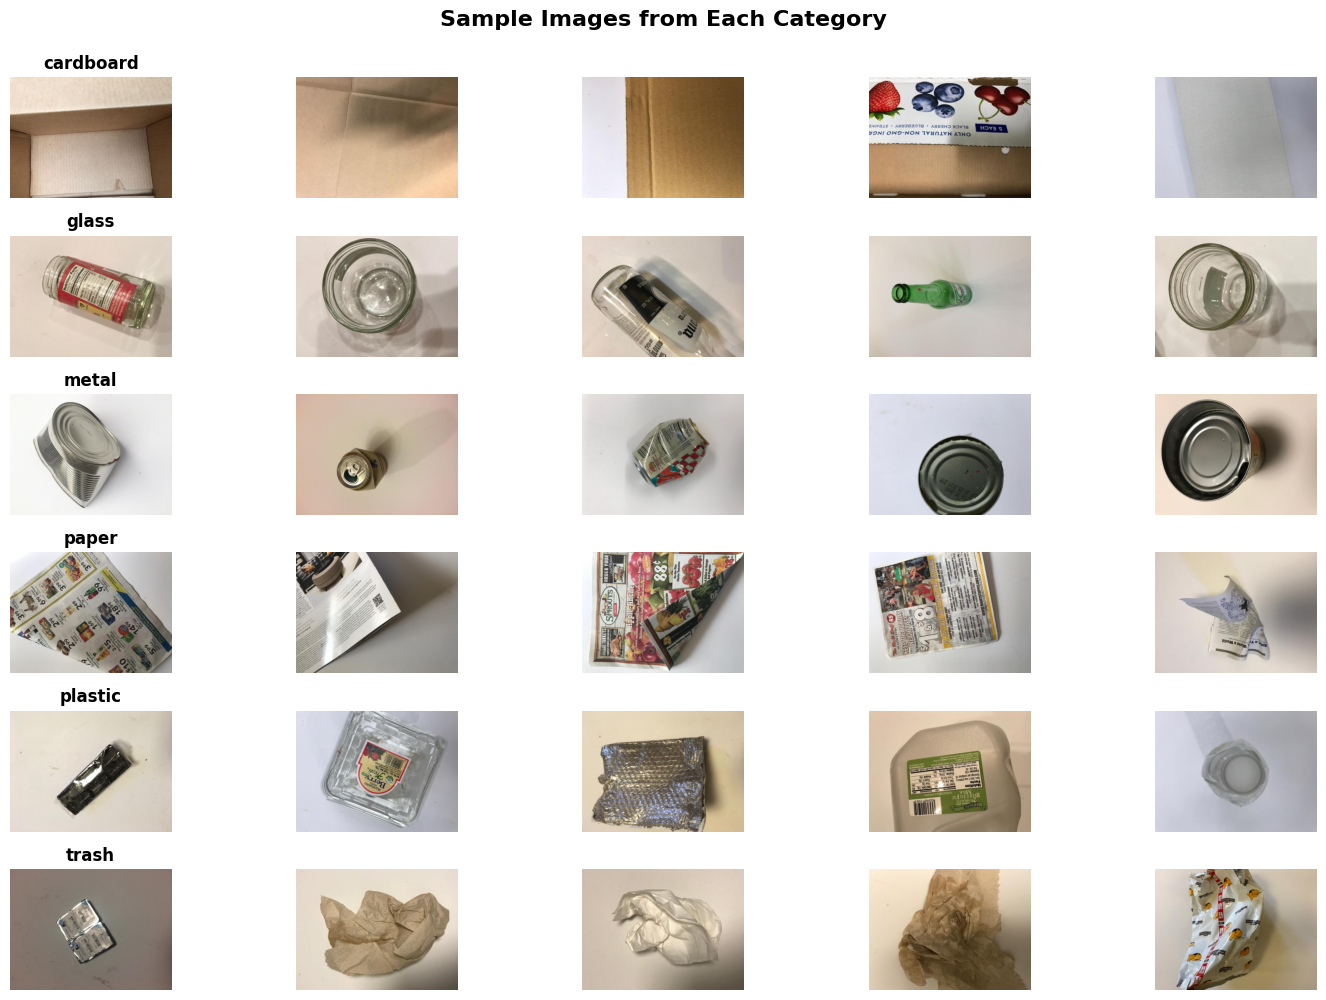

In [3]:
# Visualize random samples from each category (5 images per class)
def visualize_samples(data_dir, class_names, num_samples=5):
    """Display a grid of random sample images from each class"""
    plt.figure(figsize=(15, 10))
    for i, class_name in enumerate(class_names):
        class_dir = data_dir / class_name
        images = list(class_dir.glob('*'))
        
        # Select random images
        selected_images = np.random.choice(images, num_samples, replace=False)
        
        for j, img_path in enumerate(selected_images):
            img = Image.open(img_path)
            plt.subplot(len(class_names), num_samples, i * num_samples + j + 1)
            plt.imshow(img)
            plt.axis("off")
            if j == 0:
                plt.title(class_name, fontsize=12, fontweight='bold')
    
    plt.suptitle('Sample Images from Each Category', fontsize=16, fontweight='bold', y=0.995)
    plt.tight_layout()
    plt.show()

print("Visualizing random samples from each category...")
visualize_samples(data_dir, class_names)

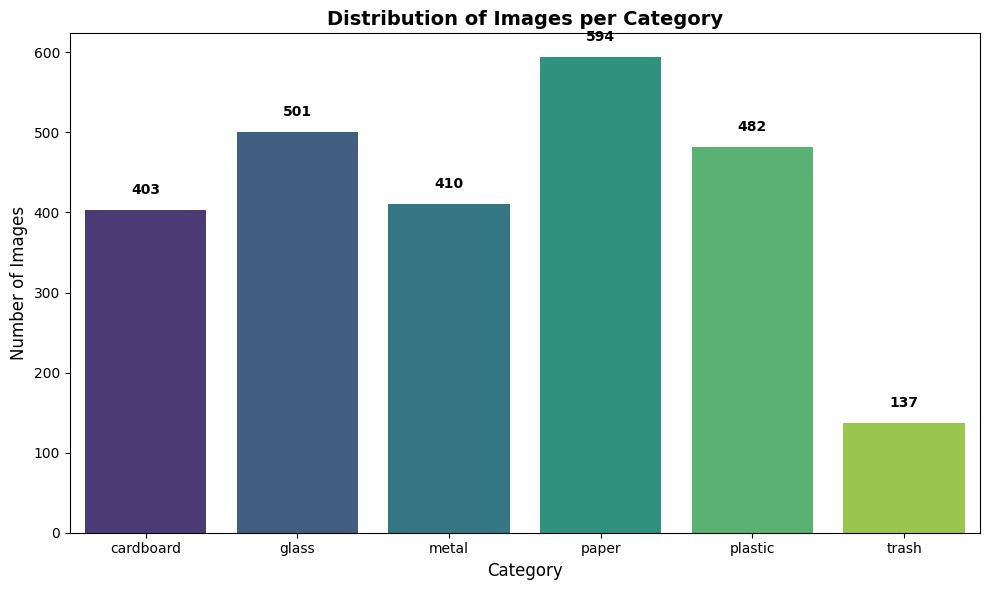


Class Distribution:
  cardboard   :  403 images
  glass       :  501 images
  metal       :  410 images
  paper       :  594 images
  plastic     :  482 images
  trash       :  137 images

Total images: 2527


In [4]:
# Analyze class distribution
image_counts = {class_name: len(list(data_dir.glob(f'{class_name}/*'))) for class_name in class_names}

plt.figure(figsize=(10, 6))
sns.barplot(x=list(image_counts.keys()), y=list(image_counts.values()), 
            palette='viridis', hue=list(image_counts.keys()), legend=False)
plt.title('Distribution of Images per Category', fontsize=14, fontweight='bold')
plt.xlabel('Category', fontsize=12)
plt.ylabel('Number of Images', fontsize=12)
plt.xticks(rotation=0)

# Add value labels on bars
for i, (category, count) in enumerate(image_counts.items()):
    plt.text(i, count + 20, str(count), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print("\nClass Distribution:")
for class_name, count in image_counts.items():
    print(f"  {class_name:<12}: {count:>4} images")
print(f"\nTotal images: {sum(image_counts.values())}")

---

## Section 3: Methodology 1 - Pure Machine Learning (The Baseline)

### 3.1 Overview

**Objective:** Establish a baseline performance using traditional machine learning without deep neural networks.

**Approach:** We employ Support Vector Machines (SVM) with Radial Basis Function (RBF) kernel as the classifier. Given that raw image data is high-dimensional (64×64×3 = 12,288 features), Principal Component Analysis (PCA) is applied for dimensionality reduction while retaining 95% of the data variance.

**Rationale:** SVMs are effective in high-dimensional spaces and capable of finding optimal decision boundaries. PCA addresses the curse of dimensionality and reduces overfitting risk.

### 3.2 Image Preprocessing and Data Preparation

Images are resized to 64×64 pixels and flattened into feature vectors. The dataset is split using stratified sampling to maintain class proportions.

In [5]:
# Pixel baseline: resize to 64 x 64 and flatten RGB values.
X_ml = []
for image_path in image_paths:
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    X_ml.append(cv2.resize(image, (64, 64)).reshape(-1))
X_ml = np.asarray(X_ml, dtype=np.float32)
X_train_ml, X_test_ml = X_ml[train_indices], X_ml[test_indices]
y_train_ml, y_test_ml = labels[train_indices], labels[test_indices]
print('Pixel feature matrix:', X_ml.shape)

Pixel feature matrix: (2527, 12288)


### 3.3 Model Training: Pipeline (StandardScaler → PCA → SVM)

We construct a pipeline that chains preprocessing and classification steps: feature scaling, dimensionality reduction, and SVM classification.

In [6]:
# Construct ML Pipeline: Scaling → PCA → SVM
pipeline_svm = Pipeline([
    ('scaler', StandardScaler()),              # Normalize features
    ('pca', PCA(n_components=0.95)),           # Keep 95% of variance
    ('svm', SVC(kernel='rbf', C=10.0, random_state=42))  # RBF kernel SVM
])

print("Training SVM Baseline Model...")
print("This may take a few moments...")
pipeline_svm.fit(X_train_ml, y_train_ml)

# Check PCA components
n_components = pipeline_svm.named_steps['pca'].n_components_
print(f"\n✓ Training completed")
print(f"  PCA reduced dimensions from {X_train_ml.shape[1]} to {n_components} components")
print(f"  Variance retained: 95%")

Training SVM Baseline Model...
This may take a few moments...



✓ Training completed
  PCA reduced dimensions from 12288 to 473 components
  Variance retained: 95%


### 3.4 K-Fold Cross-Validation (K=5)

To ensure model generalization and assess variation across folds, we perform 5-Fold cross-validation on the training data. This technique splits the training set into 5 folds, trains on 4 folds, and validates on the remaining fold, repeating 5 times.

In [7]:
# Perform 5-Fold Cross-Validation
print("Performing 5-Fold Cross-Validation...")
print("This validates model robustness across different data splits...")

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    pipeline_svm, 
    X_train_ml, 
    y_train_ml, 
    cv=kfold, 
    scoring='accuracy',
    n_jobs=N_JOBS
)

print(f"\n✓ Cross-Validation Results:")
print(f"  Fold Accuracies: {[f'{score:.4f}' for score in cv_scores]}")
print(f"\n  Mean CV Accuracy: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Performing 5-Fold Cross-Validation...
This validates model robustness across different data splits...



✓ Cross-Validation Results:
  Fold Accuracies: ['0.6543', '0.6114', '0.6163', '0.6584', '0.6114']

  Mean CV Accuracy: 0.6304 ± 0.0213


### 3.5 Test Set Evaluation

We evaluate the trained model on the held-out test set to assess performance on this dataset.

In [8]:
# Evaluate on test set
print("Evaluating SVM Model on Test Set...")
y_pred_svm = pipeline_svm.predict(X_test_ml)
acc_svm = accuracy_score(y_test_ml, y_pred_svm)

print(f"\n{'='*60}")
print(f"METHODOLOGY 1: PURE ML (SVM + PCA) - TEST SET RESULTS")
print(f"{'='*60}")
print(f"Test Accuracy: {acc_svm:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test_ml, y_pred_svm, target_names=class_names))
print(f"{'='*60}")

Evaluating SVM Model on Test Set...



METHODOLOGY 1: PURE ML (SVM + PCA) - TEST SET RESULTS
Test Accuracy: 0.6443

Classification Report:
              precision    recall  f1-score   support

   cardboard       0.72      0.70      0.71        81
       glass       0.50      0.51      0.50       100
       metal       0.59      0.62      0.61        82
       paper       0.74      0.70      0.72       119
     plastic       0.65      0.70      0.67        97
       trash       0.73      0.59      0.65        27

    accuracy                           0.64       506
   macro avg       0.66      0.64      0.64       506
weighted avg       0.65      0.64      0.65       506



---
## Section 4: Hybrid ResNet50 + SVM

A frozen ResNet50 pretrained on ImageNet converts each 224 x 224 RGB image into a 2,048-dimensional feature vector. An RBF-kernel SVM learns the six-class classification task using those vectors. ResNet50 is not fine-tuned on this dataset.

The holdout images are exactly the same as for the pixel baseline. No random augmentation is applied to evaluation images or feature extraction, so evaluation does not depend on a random transform of each image.

### 4.2 Initialize ResNet50 Feature Extractor

ResNet50 is loaded with pre-trained ImageNet weights. The top classification layer is removed, and Global Average Pooling is used to extract feature vectors.

In [9]:
# Load ResNet50 pre-trained on ImageNet (without top classification layer)
print("Loading ResNet50 (pre-trained on ImageNet)...")
base_model_resnet = ResNet50(
    input_shape=(224, 224, 3),
    include_top=False,           # Remove final classification layer
    weights='imagenet',          # Use ImageNet pre-trained weights
    pooling='avg'                # Global Average Pooling
)

# Freeze all layers (we only use ResNet50 as a feature extractor)
base_model_resnet.trainable = False

print(f"✓ ResNet50 loaded successfully")
print(f"  Total layers: {len(base_model_resnet.layers)}")
print(f"  All layers frozen (trainable=False)")
print(f"  Output feature dimensions: {base_model_resnet.output_shape}")

Loading ResNet50 (pre-trained on ImageNet)...


✓ ResNet50 loaded successfully
  Total layers: 176
  All layers frozen (trainable=False)
  Output feature dimensions: (None, 2048)


### 4.3 Shared split and deterministic preprocessing

Both generators use the shared split from Section 2, RGB inputs and ResNet50-specific preprocessing. Shuffling is disabled to keep features aligned with labels. Random augmentation is deliberately omitted from this fixed-feature comparison.

In [10]:
IMG_SIZE_RESNET = 224
BATCH_SIZE = 32
def frame_for(indices):
    return pd.DataFrame({
        'filename': [str(image_paths[i]) for i in indices],
        'class': [class_names[labels[i]] for i in indices]
    })

generator = ImageDataGenerator(preprocessing_function=preprocess_input)
generator_kwargs = dict(
    target_size=(IMG_SIZE_RESNET, IMG_SIZE_RESNET), batch_size=BATCH_SIZE,
    class_mode='sparse', classes=class_names, shuffle=False, color_mode='rgb'
)
train_generator_resnet = generator.flow_from_dataframe(frame_for(train_indices), **generator_kwargs)
validation_generator_resnet = generator.flow_from_dataframe(frame_for(test_indices), **generator_kwargs)
assert train_generator_resnet.class_indices == validation_generator_resnet.class_indices
assert train_generator_resnet.samples == len(train_indices)
assert validation_generator_resnet.samples == len(test_indices)

Found 2021 validated image filenames belonging to 6 classes.


Found 506 validated image filenames belonging to 6 classes.


### 4.4 Extract Deep Learning Features

We pass all images through the ResNet50 network to extract high-level feature representations. This is a one-time operation that converts images into dense feature vectors.

In [11]:
# Extract features from training data using ResNet50
print("Extracting features from training data...")
print("This process passes all images through ResNet50...")

X_features_train_resnet = []
y_features_train_resnet = []

for i in range(len(train_generator_resnet)):
    X_batch, y_batch = train_generator_resnet[i]
    features = base_model_resnet.predict(X_batch, verbose=0)
    X_features_train_resnet.extend(features)
    y_features_train_resnet.extend(y_batch)
    
    if (i + 1) % 10 == 0:
        print(f"  Processed {(i + 1) * BATCH_SIZE} / {train_generator_resnet.samples} training images...")

X_features_train_resnet = np.array(X_features_train_resnet)
y_features_train_resnet = np.array(y_features_train_resnet)

print(f"✓ Training features extracted")
print(f"  Shape: {X_features_train_resnet.shape}")

# Extract features from validation data
print("\nExtracting features from validation data...")
X_features_val_resnet = []
y_features_val_resnet = []

for i in range(len(validation_generator_resnet)):
    X_batch, y_batch = validation_generator_resnet[i]
    features = base_model_resnet.predict(X_batch, verbose=0)
    X_features_val_resnet.extend(features)
    y_features_val_resnet.extend(y_batch)

X_features_val_resnet = np.array(X_features_val_resnet)
y_features_val_resnet = np.array(y_features_val_resnet)

print(f"✓ Validation features extracted")
print(f"  Shape: {X_features_val_resnet.shape}")
print(f"\n✓ Feature extraction completed successfully!")

Extracting features from training data...
This process passes all images through ResNet50...


  Processed 320 / 2021 training images...


  Processed 640 / 2021 training images...


  Processed 960 / 2021 training images...


  Processed 1280 / 2021 training images...


  Processed 1600 / 2021 training images...


  Processed 1920 / 2021 training images...


✓ Training features extracted
  Shape: (2021, 2048)

Extracting features from validation data...


✓ Validation features extracted
  Shape: (506, 2048)

✓ Feature extraction completed successfully!


### 4.5 Train SVM Classifier on ResNet50 Features

With the deep learning features extracted, we now train an SVM classifier to perform the final classification.

In [12]:
# Train SVM on ResNet50 features
print("Training SVM classifier on ResNet50 features...")
svm_resnet = SVC(kernel='rbf', C=10.0, random_state=42)
svm_resnet.fit(X_features_train_resnet, y_features_train_resnet)

print("✓ SVM training completed")

Training SVM classifier on ResNet50 features...


✓ SVM training completed


### 4.6 K-Fold Cross-Validation on ResNet50 Features

We perform 5-Fold cross-validation on the extracted features to validate the hybrid model's robustness.

In [13]:
# Perform 5-Fold Cross-Validation on ResNet50 features
print("Performing 5-Fold Cross-Validation on ResNet50 features...")
print("This validates the hybrid model's generalization capability...")

kfold_resnet = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores_resnet = cross_val_score(
    svm_resnet, 
    X_features_train_resnet, 
    y_features_train_resnet, 
    cv=kfold_resnet, 
    scoring='accuracy',
    n_jobs=N_JOBS
)

print(f"\n✓ Cross-Validation Results:")
print(f"  Fold Accuracies: {[f'{score:.4f}' for score in cv_scores_resnet]}")
print(f"\n  Mean CV Accuracy: {cv_scores_resnet.mean():.4f} ± {cv_scores_resnet.std():.4f}")

Performing 5-Fold Cross-Validation on ResNet50 features...
This validates the hybrid model's generalization capability...



✓ Cross-Validation Results:
  Fold Accuracies: ['0.9086', '0.9158', '0.9109', '0.9059', '0.9010']

  Mean CV Accuracy: 0.9085 ± 0.0050


### 4.7 Holdout evaluation

The frozen feature extractor and trained SVM are evaluated on the common held-out image split. This is a coursework benchmark on this dataset, not an estimate of performance in an operational sorting facility.

In [14]:
y_pred_hybrid_resnet = svm_resnet.predict(X_features_val_resnet)
acc_hybrid_resnet = accuracy_score(y_features_val_resnet, y_pred_hybrid_resnet)
assert np.array_equal(y_features_val_resnet.astype(int), y_test_ml)
print(f'ResNet50 + SVM holdout accuracy: {acc_hybrid_resnet:.4f}')
print(classification_report(y_features_val_resnet, y_pred_hybrid_resnet,
                            target_names=class_names, zero_division=0))

ResNet50 + SVM holdout accuracy: 0.9269
              precision    recall  f1-score   support

   cardboard       0.97      0.96      0.97        81
       glass       0.91      0.91      0.91       100
       metal       0.89      0.94      0.91        82
       paper       0.95      0.96      0.95       119
     plastic       0.91      0.90      0.90        97
       trash       0.96      0.81      0.88        27

    accuracy                           0.93       506
   macro avg       0.93      0.91      0.92       506
weighted avg       0.93      0.93      0.93       506



---

## Section 5: Comparative Analysis & Conclusion

### 5.1 Performance Comparison

We compare the two methodologies to identify the best performing model for garbage classification.

In [15]:
results_df = pd.DataFrame([
    {'Methodology': 'Pixels + PCA + SVM', 'Accuracy': acc_svm,
     'Macro F1': f1_score(y_test_ml, y_pred_svm, average='macro'),
     'Training CV mean': cv_scores.mean(), 'Training CV std': cv_scores.std()},
    {'Methodology': 'ResNet50 + SVM', 'Accuracy': acc_hybrid_resnet,
     'Macro F1': f1_score(y_test_ml, y_pred_hybrid_resnet, average='macro'),
     'Training CV mean': cv_scores_resnet.mean(), 'Training CV std': cv_scores_resnet.std()}
])
print(results_df.to_string(index=False))
results_df.to_csv(REPORT_DIR / 'model_comparison.csv', index=False)
summary = {
    'seed': SEED, 'dataset': 'asdasdasasdas/garbage-classification',
    'images': len(image_paths), 'train_images': len(train_indices),
    'holdout_images': len(test_indices), 'classes': class_names,
    'comparison': results_df.to_dict(orient='records'),
    'protocol': 'Shared stratified 80/20 split; five-fold stratified CV on training only; no augmentation.'
}
(REPORT_DIR / 'metrics.json').write_text(json.dumps(summary, indent=2))

       Methodology  Accuracy  Macro F1  Training CV mean  Training CV std
Pixels + PCA + SVM  0.644269  0.644923          0.630369         0.021344
    ResNet50 + SVM  0.926877  0.920953          0.908461         0.004951


809

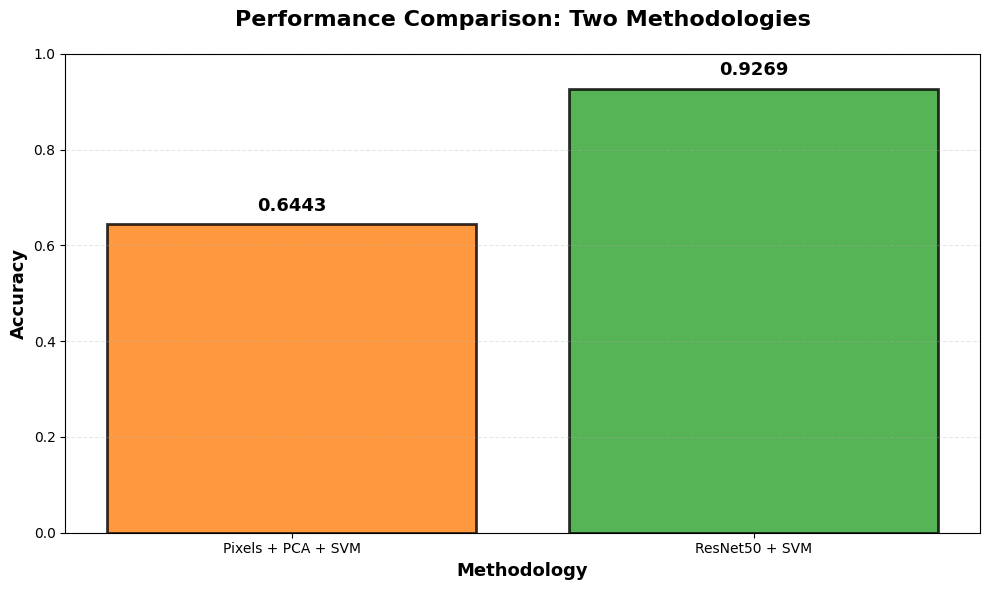

In [16]:
# Visualize comparison
plt.figure(figsize=(10, 6))

colors = ['#ff7f0e', '#2ca02c']
bars = plt.bar(results_df['Methodology'], results_df['Accuracy'], 
               color=colors, alpha=0.8, edgecolor='black', linewidth=2)

plt.title('Performance Comparison: Two Methodologies', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Methodology', fontsize=13, fontweight='bold')
plt.ylabel('Accuracy', fontsize=13, fontweight='bold')
plt.ylim([0, 1.0])
plt.grid(axis='y', alpha=0.3, linestyle='--')

# Add value labels
for bar, acc in zip(bars, results_df['Accuracy']):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.02,
             f'{acc:.4f}',
             ha='center', va='bottom', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURE_DIR / 'model_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

### 5.2 Confusion matrix for ResNet50 + SVM

The matrix shows predictions for the same held-out images used by the baseline.

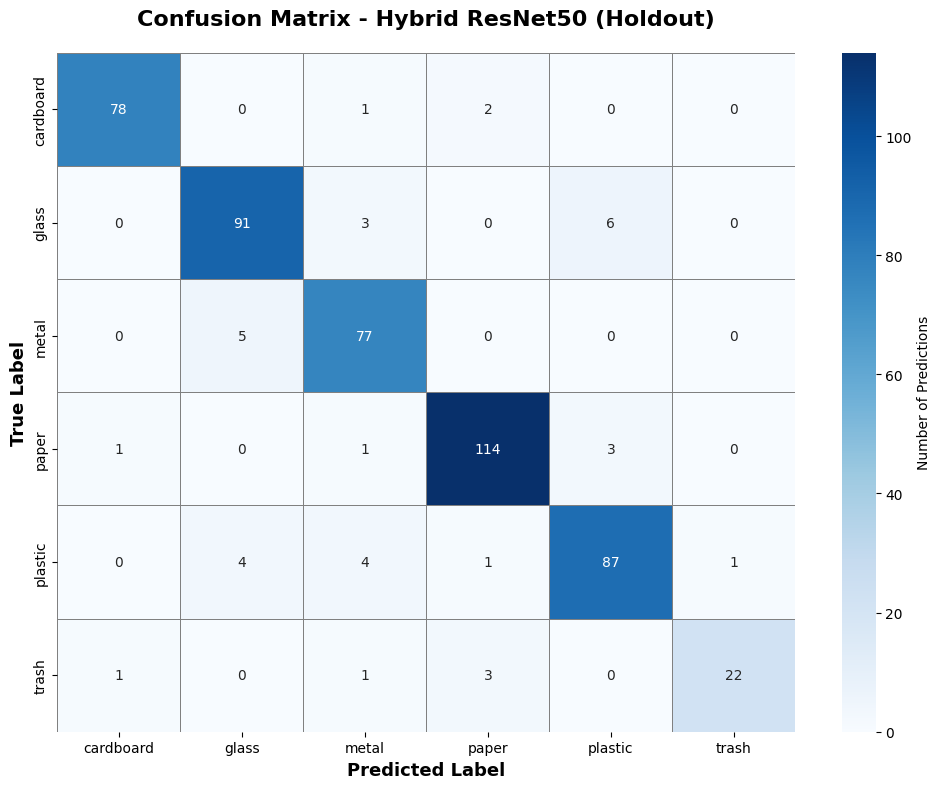


PER-CLASS PERFORMANCE ANALYSIS
cardboard    | Correct:   78/81   | Accuracy: 0.9630
glass        | Correct:   91/100  | Accuracy: 0.9100
metal        | Correct:   77/82   | Accuracy: 0.9390
paper        | Correct:  114/119  | Accuracy: 0.9580
plastic      | Correct:   87/97   | Accuracy: 0.8969
trash        | Correct:   22/27   | Accuracy: 0.8148


In [17]:
# Generate confusion matrix for the best model (Hybrid ResNet50)
cm = confusion_matrix(y_features_val_resnet, y_pred_hybrid_resnet)

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Number of Predictions'},
            linewidths=0.5, linecolor='gray')

plt.title('Confusion Matrix - Hybrid ResNet50 (Holdout)', 
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Predicted Label', fontsize=13, fontweight='bold')
plt.ylabel('True Label', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'confusion_matrix.png', dpi=160, bbox_inches='tight')
plt.show()

# Per-class accuracy analysis
print("\n" + "="*60)
print("PER-CLASS PERFORMANCE ANALYSIS")
print("="*60)
for i, class_name in enumerate(class_names):
    class_correct = cm[i, i]
    class_total = cm[i, :].sum()
    class_accuracy = class_correct / class_total if class_total > 0 else 0
    print(f"{class_name:<12} | Correct: {class_correct:>4}/{class_total:<4} | Accuracy: {class_accuracy:.4f}")
print("="*60)

### 5.3 Interpretation and limitations

The table above reports the measured results from this execution. A shared split makes the two approaches directly comparable; stratified cross-validation evaluates variation within the training partition. The confusion matrix and macro F1 expose class-specific weaknesses that overall accuracy can hide.

This is an educational prototype. A small, imbalanced dataset of mostly isolated objects does not represent mixed waste, cluttered backgrounds or industrial camera conditions. There is no unknown-object rejection: an out-of-distribution image will still receive one of the six labels. Further work should include duplicate-image audits, an independent external test set, uncertainty estimation and a deployment-specific evaluation. No production deployment or IoT hardware integration is claimed.

---
## Section 6: Single-image inference

The following function uses the frozen ResNet50 feature extractor and its SVM classifier. All images are converted to RGB, including grayscale and transparent PNG inputs. This is a demonstration of inference, not a separate accuracy benchmark.

In [18]:
def predict_image(image_path):
    """
    Classify a garbage image using the hybrid model (Hybrid ResNet50).
    
    Parameters:
        image_path (str): Path to the image file
        
    Returns:
        str: Predicted class label
    """
    try:
        # Load and preprocess image
        img = Image.open(image_path).convert("RGB")
        img_array = img.resize((224, 224))
        img_array = np.array(img_array).astype('float32')
        img_array = np.expand_dims(img_array, axis=0)
        
        # Apply ResNet50 preprocessing
        img_preprocessed = preprocess_input(img_array)
        
        # Extract features using ResNet50
        features = base_model_resnet.predict(img_preprocessed, verbose=0)
        
        # Predict using SVM
        prediction_idx = svm_resnet.predict(features)[0]
        predicted_class = class_names[int(prediction_idx)]
        
        # Display result
        plt.figure(figsize=(8, 8))
        plt.imshow(img)
        plt.axis('off')
        plt.title(f'Predicted Class: {predicted_class}', 
                  fontsize=16, fontweight='bold', pad=20,
                  bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.8))
        plt.tight_layout()
        plt.show()
        
        return predicted_class
        
    except Exception as e:
        print(f"Error processing image: {e}")
        return None

print("✓ Inference function ready!")

✓ Inference function ready!


### 6.2 Demonstration on one holdout image

This single prediction illustrates usage; aggregate performance is reported in Section 5.

True class: plastic


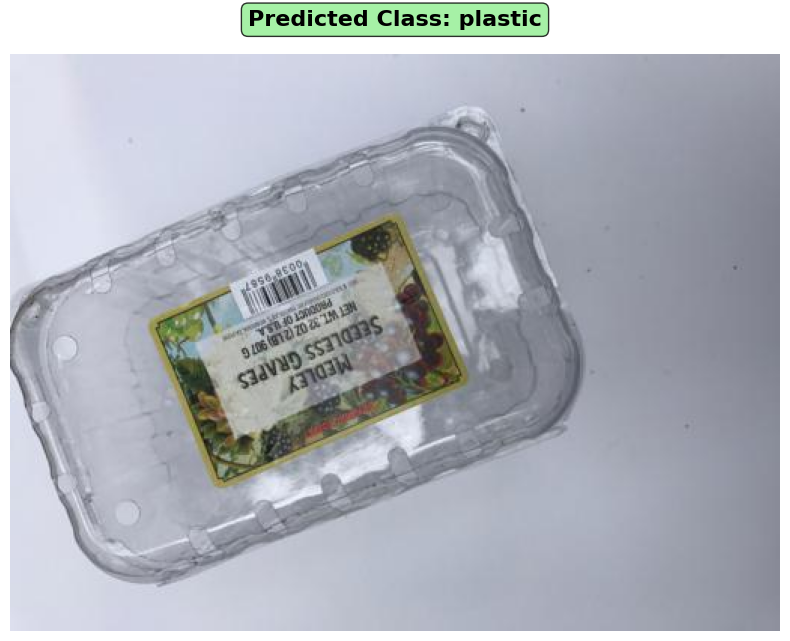

Predicted class: plastic


In [19]:
example_index = int(test_indices[0])
print('True class:', class_names[labels[example_index]])
prediction = predict_image(str(image_paths[example_index]))
print('Predicted class:', prediction)